# A2. 트랜스포머와 셀프 어텐션: GPT-2 를 손으로 계산하기

- 영상: [16:03 Transformer architecture & self-attention](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=963s) ~ 28:27 [2]
- 슬라이드: `data/lecture02.pdf` 24–60쪽 [1]. 32쪽은 "여기서 길을 잃으면 강의 나머지가 아주 헷갈린다"고 강조합니다.
- 읽을거리: [Attention Is All You Need](https://arxiv.org/abs/1706.03762) [3] (`data/` 에 PDF)

## 목표

1. 셀프 어텐션 한 층을 직접 짜고, PyTorch 내장 함수와 결과를 맞춥니다.
2. 여러 머리 어텐션, layer norm, MLP, 잔차 연결을 이어 붙여 **GPT-2 전체를 직접 계산**하고, Hugging Face 모델과 logit 이 같은지 확인합니다.
3. 실제 GPT-2 의 어텐션이 어디를 보는지 그림으로 봅니다.

**이 노트북이 답하는 질문**: 트랜스포머 안에서 숫자는 어떤 순서로 흘러가고, 셀프 어텐션은 정확히 무엇을 계산하나?

**읽는 법**: 개념 하나마다 한 줄 정의 → 왜 필요한가 → 숫자로 따라가기 → 그림 → 그림에서 볼 것 → 식과 근거 → 직접 바꿔 보기 순서입니다.
`[3]` 같은 번호는 맨 아래 **출처** 절의 번호입니다.

In [1]:
import os, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")          # 설치 환경에 따라 나오는 경고 문구를 숨긴다

import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False      # 비교를 정확히 하려고 끈다
_ = torch.manual_seed(0)

tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
hf = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()
sd = {k: v.detach() for k, v in hf.state_dict().items()}
cfg = hf.config
print("device:", device, "| 층", cfg.n_layer, "| head", cfg.n_head, "| 차원", cfg.n_embd)

device: cpu | 층 12 | head 12 | 차원 768


In [2]:
# 그림 도구 모음입니다. 펼쳐 보지 않아도 됩니다. 본문은 draw_xxx() 를 한 줄씩 부릅니다.
# 팔레트: Okabe-Ito. 그림 안 글자는 영어로 씁니다.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 100})
C = dict(orange="#E69F00", sky="#56B4E9", green="#009E73", yellow="#F0E442",
         blue="#0072B2", red="#D55E00", purple="#CC79A7", black="#000000", grey="#BBBBBB")


def _box(ax, x, y, text, w=1.6, h=0.6, fc="#FFFFFF", ec="#000000", fs=9.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03", fc=fc, ec=ec, lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)


def _arrow(ax, x1, y1, x2, y2, color="#000000", rad=0.0, lw=1.0):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, color=color,
                                 lw=lw, connectionstyle=f"arc3,rad={rad}"))


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(13, 3.8))
    items = [("token\nIDs", 0, C["grey"], "1-3"), ("embedding\n+ position", 1.5, C["sky"], "1-3, 1-4"),
             ("LayerNorm", 3.0, C["grey"], "3-2"), ("multi-head\nattention", 4.5, C["orange"], "1-5 ~ 2"),
             ("+", 5.8, C["green"], "3-1"), ("LayerNorm", 7.0, C["grey"], "3-2"), ("MLP", 8.6, C["sky"], "3-3"),
             ("+", 9.9, C["green"], "3-1"), ("final\nLayerNorm", 11.3, C["grey"], "4"),
             ("x wte^T\n-> logits", 12.8, C["blue"], "4")]
    for name, x, col, sec in items:
        w = 0.55 if name == "+" else 1.2
        _box(ax, x, 0, name, w=w, h=0.8, fc=col + "55", fs=9)
        ax.text(x, -0.62, sec, ha="center", va="top", fontsize=8.5, color="#555555")
    for (a, b) in zip(items[:-1], items[1:]):
        wa = 0.28 if a[0] == "+" else 0.6
        wb = 0.28 if b[0] == "+" else 0.6
        _arrow(ax, a[1] + wa, 0, b[1] - wb, 0)
    # 잔차 연결: 블록 입력을 + 로 바로 보낸다
    _arrow(ax, 2.3, 0.4, 5.8, 0.42, color=C["green"], rad=-0.35)
    _arrow(ax, 6.2, 0.4, 9.9, 0.42, color=C["green"], rad=-0.35)
    ax.text(4.0, 1.25, "residual (skip) path", color=C["green"], fontsize=9, ha="center")
    ax.add_patch(Rectangle((2.2, -1.05), 8.15, 2.65, fill=False, ls="--", ec="#555555"))
    ax.text(10.3, 1.5, "transformer block, repeated 12 times", ha="right", va="top", fontsize=9.5, color="#555555")
    ax.text(-0.5, -1.25, "small numbers under boxes = section of this notebook", fontsize=8.5, color="#555555")
    ax.set_xlim(-0.8, 13.6); ax.set_ylim(-1.45, 1.8); ax.axis("off")
    ax.set_title("A2 concept map: how numbers flow through GPT-2")
    plt.show()


def draw_dot_product():
    vecs = {"a": (np.array([2.0, 1.0]), C["black"]), "b": (np.array([1.8, 1.2]), C["blue"]),
            "c": (np.array([-1.0, 2.0]), C["green"]), "d": (np.array([-2.0, -1.0]), C["red"])}
    a = vecs["a"][0]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    for name, (v, col) in vecs.items():
        ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
        lab = f"{name} = ({v[0]:g}, {v[1]:g})" + ("" if name == "a" else f"\na . {name} = {a @ v:g}")
        off = {"a": (8, -14), "b": (6, 6), "c": (-30, 8), "d": (-20, -30)}[name]
        ax.annotate(lab, v, textcoords="offset points", xytext=off, fontsize=9, color=col)
    ax.axhline(0, color="#DDDDDD", lw=0.8, zorder=0); ax.axvline(0, color="#DDDDDD", lw=0.8, zorder=0)
    ax.set_xlim(-3, 3.3); ax.set_ylim(-2.2, 3); ax.set_aspect("equal")
    ax.set_title("Dot product: same direction -> large,\nright angle -> 0, opposite -> negative")
    fig.tight_layout(); plt.show()


def draw_matmul_shapes(T=5, D=768, d=64):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    # X (T x D)
    ax.add_patch(Rectangle((0, 1.0), 3.2, 1.5, fc=C["sky"] + "55", ec="black"))
    ax.add_patch(Rectangle((0, 1.9), 3.2, 0.3, fc=C["orange"], ec="black"))
    ax.text(1.6, 2.7, f"X: ({T}, {D})\n{T} tokens x {D} numbers", ha="center", fontsize=9.5)
    ax.text(3.6, 1.75, "@", fontsize=16, ha="center", va="center")
    # W (D x d)
    ax.add_patch(Rectangle((4.0, 0.0), 1.0, 3.2, fc=C["green"] + "44", ec="black"))
    ax.add_patch(Rectangle((4.35, 0.0), 0.3, 3.2, fc=C["orange"], ec="black"))
    ax.text(4.5, 3.35, f"W: ({D}, {d})", ha="center", fontsize=9.5)
    ax.text(5.5, 1.75, "=", fontsize=16, ha="center", va="center")
    # Q (T x d)
    ax.add_patch(Rectangle((6.0, 1.0), 1.0, 1.5, fc=C["purple"] + "44", ec="black"))
    ax.add_patch(Rectangle((6.35, 1.9), 0.3, 0.3, fc=C["red"], ec="black"))
    ax.text(6.5, 2.7, f"Q: ({T}, {d})", ha="center", fontsize=9.5)
    ax.text(7.4, 2.05, "one orange row . one orange column\n= ONE number (red cell)", fontsize=9, va="center")
    ax.text(0, -0.45, f"Rule: the inner sizes must match ({D} and {D}); the result keeps the outer sizes ({T} and {d}).",
            fontsize=9.5)
    ax.set_xlim(-0.2, 10.3); ax.set_ylim(-0.7, 3.7); ax.axis("off")
    ax.set_title("Matrix multiply = many dot products at once")
    plt.show()


def draw_embedding_lookup(ids, toks, vocab=50257):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.add_patch(Rectangle((0, 0), 2.2, 4.0, fc="#F2F2F2", ec="black"))
    ax.text(1.1, 4.15, f"wte table: {vocab:,} rows x 768", ha="center", fontsize=9.5)
    cols = [C["orange"], C["blue"], C["green"], C["purple"], C["red"], C["sky"]]
    rank = {tid: r for r, tid in enumerate(sorted(ids))}
    for i, (tid, t) in enumerate(zip(ids, toks)):
        y = 4.0 - (rank[tid] + 1) * 4.0 / (len(ids) + 1)      # 줄은 고르게 그린다 (실제 자리는 표 전체에 흩어져 있음)
        ax.add_patch(Rectangle((0, y - 0.04), 2.2, 0.08, fc=cols[i % 6], ec="none"))
        ax.text(-0.1, y, f"row {tid}", ha="right", va="center", fontsize=8.5, color=cols[i % 6])
        yo = 3.2 - i * 0.55
        ax.add_patch(Rectangle((5.0, yo - 0.2), 2.6, 0.4, fc=cols[i % 6], ec="black"))
        ax.text(7.75, yo, f"'{t}'", va="center", fontsize=9.5)
        _arrow(ax, 2.25, y, 4.95, yo, color=cols[i % 6])
    ax.text(6.3, 3.75, f"output: ({len(ids)}, 768)\none row per token", ha="center", fontsize=9.5)
    ax.text(1.1, -0.2, "rows drawn evenly spaced, not to scale", ha="center", va="top", fontsize=8.5, color="#555555")
    ax.set_xlim(-1.4, 9.2); ax.set_ylim(-0.6, 4.5); ax.axis("off")
    ax.set_title("Embedding = look up one row of the table per token ID")
    plt.show()


def draw_word_similarity(words, S):
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    im = ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(words)), words, rotation=45, ha="right"); ax.set_yticks(range(len(words)), words)
    for i in range(len(words)):
        for j in range(len(words)):
            ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if S[i, j] > 0.6 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, label="cosine similarity")
    ax.set_title("GPT-2 token embeddings: similar words\nhave similar vectors")
    fig.tight_layout(); plt.show()


def draw_position_similarity(S):
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    im = ax.imshow(S, cmap="viridis", vmin=-0.2, vmax=1)
    fig.colorbar(im, ax=ax, fraction=0.046, label="cosine similarity")
    ax.set_xlabel("position j"); ax.set_ylabel("position i")
    ax.set_title(f"GPT-2 position vectors (wpe), positions 0-{len(S) - 1}")
    fig.tight_layout(); plt.show()


def draw_qkv_steps(labels, q, K, V):
    s = K @ q / np.sqrt(len(q)); w = np.exp(s) / np.exp(s).sum(); out = w @ V
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.15]})
    ax[0].bar(labels, s, color=C["grey"])
    for i, v in enumerate(s):
        ax[0].text(i, v + 0.03, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
    ax[0].set_title("1. score = q . k_j / sqrt(d)\n'how relevant is token j?'")
    ax[0].set_ylim(min(0, s.min()) - 0.1, s.max() * 1.3)
    ax[1].bar(labels, w, color=C["orange"])
    for i, v in enumerate(w):
        ax[1].text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
    ax[1].set_title("2. weights = softmax(scores)\n(sum = 1)")
    ax[1].set_ylim(0, w.max() * 1.3)
    cols = [C["sky"], C["blue"], C["green"], C["purple"]]
    for i, (v, col) in enumerate(zip(V, cols)):
        ax[2].annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.2, alpha=0.6))
        ax[2].annotate(f"v_{labels[i]} (w={w[i]:.2f})", v, textcoords="offset points", xytext=(4, 4), fontsize=8.5, color=col)
    ax[2].annotate("", xy=out, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=C["red"], lw=2.5))
    ax[2].text(1.2, -0.45, f"output (red) = sum w_j v_j\n= ({out[0]:.2f}, {out[1]:.2f})", fontsize=9, color=C["red"])
    ax[2].axhline(0, color="#DDDDDD", lw=0.8, zorder=0); ax[2].axvline(0, color="#DDDDDD", lw=0.8, zorder=0)
    ax[2].set_xlim(-0.6, 2.9); ax[2].set_ylim(-1.3, 1.9); ax[2].set_aspect("equal")
    ax[2].set_title("3. mix the values with the weights")
    fig.tight_layout(); plt.show()


def draw_causal_mask(labels):
    T = len(labels)
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    for i in range(T):
        for j in range(T):
            ok = j <= i
            ax.add_patch(Rectangle((j, T - 1 - i), 1, 1, fc=(C["blue"] + "88") if ok else "#EEEEEE", ec="white", lw=2))
            ax.text(j + 0.5, T - 0.5 - i, "see" if ok else "future", ha="center", va="center", fontsize=8.5,
                    color="black" if ok else "#888888")
    ax.set_xticks(np.arange(T) + 0.5, labels, rotation=45, ha="right")
    ax.set_yticks(np.arange(T) + 0.5, labels[::-1])
    ax.set_xlabel("key: token being looked at"); ax.set_ylabel("query: token doing the looking")
    ax.set_xlim(0, T); ax.set_ylim(0, T)
    ax.set_title("Causal mask: each token sees itself\nand the tokens before it")
    fig.tight_layout(); plt.show()


def draw_attention_heatmap(A, labels, title):
    T = len(labels)
    fig, ax = plt.subplots(figsize=(4.8 if T <= 6 else 6.5, 4.4 if T <= 6 else 5.8))
    ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    if T <= 8:
        for i in range(T):
            for j in range(T):
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                        color="white" if A[i, j] > 0.6 else "black")
    if any(labels):
        ax.set_xticks(range(T), labels, rotation=90 if T > 8 else 45, ha="center" if T > 8 else "right",
                      fontsize=8.5 if T > 8 else 10)
        ax.set_yticks(range(T), labels, fontsize=8.5 if T > 8 else 10)
        ax.set_xlabel("key (looked-at token)"); ax.set_ylabel("query (current token)")
    else:
        ax.set_xlabel("key position"); ax.set_ylabel("query position")
    ax.set_title(title)
    fig.tight_layout(); plt.show()


def draw_scaling(seed=0):
    g = np.random.default_rng(seed)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for dd, col in [(8, C["blue"]), (64, C["orange"]), (512, C["red"])]:
        dots = (g.standard_normal((20000, dd)) * g.standard_normal((20000, dd))).sum(1)
        ax[0].hist(dots, bins=120, range=(-80, 80), histtype="step", lw=1.5, color=col,
                   label=f"d = {dd}: spread (sd) = {dots.std():.1f}")
    ax[0].set_xlabel("q . k  (NOT divided)"); ax[0].set_ylabel("count")
    ax[0].set_title("A. bigger d -> dot products spread wider")
    ax[0].legend(fontsize=8.5, frameon=False)
    dd = 512
    s = (g.standard_normal((8, dd)) * g.standard_normal(dd)).sum(1)
    w_raw = np.exp(s - s.max()); w_raw /= w_raw.sum()
    w_sc = np.exp(s / np.sqrt(dd) - (s / np.sqrt(dd)).max()); w_sc /= w_sc.sum()
    x = np.arange(8)
    ax[1].bar(x - 0.2, w_raw, width=0.4, color=C["red"], label="softmax(q . k)")
    ax[1].bar(x + 0.2, w_sc, width=0.4, color=C["blue"], label="softmax(q . k / sqrt(d))")
    ax[1].set_xticks(x, [f"key {i + 1}" for i in x])
    ax[1].set_ylabel("attention weight")
    ax[1].set_title("B. d = 512: without dividing, one key takes ~all")
    ax[1].legend(fontsize=8.5, frameon=False)
    fig.tight_layout(); plt.show()


def draw_multihead():
    T = 6
    pats = {"head 1: previous token": np.eye(T, k=-1) + np.diag([1] + [0] * (T - 1)),
            "head 2: first token": np.tril(np.zeros((T, T))) + np.eye(T, 1, 0) * 0,
            "head 3: itself": np.eye(T),
            "head 4: spread evenly": np.tril(np.ones((T, T)))}
    pats["head 2: first token"] = np.zeros((T, T)); pats["head 2: first token"][:, 0] = 1
    fig = plt.figure(figsize=(13, 4.6))
    gs = fig.add_gridspec(2, 5, height_ratios=[0.55, 1.4], width_ratios=[1, 1, 1, 1, 1.15])
    bar = fig.add_subplot(gs[0, :])
    for h in range(12):
        bar.add_patch(Rectangle((h * 64, 0), 64, 1, fc=[C["sky"], C["orange"]][h % 2] + "88", ec="black"))
        bar.text(h * 64 + 32, 0.5, f"head {h + 1}\n64", ha="center", va="center", fontsize=8.5)
    bar.set_xlim(0, 768); bar.set_ylim(0, 1); bar.set_yticks([])
    bar.set_xticks([0, 192, 384, 576, 768]); bar.set_xlabel("the 768 numbers of one token's q (and k, v) are cut into 12 pieces")
    for i, (name, P) in enumerate(pats.items()):
        a = fig.add_subplot(gs[1, i])
        P = P / P.sum(1, keepdims=True)
        a.imshow(P, cmap="Blues", vmin=0, vmax=1)
        a.set_xticks([]); a.set_yticks([]); a.set_title(name, fontsize=9.5)
    t = fig.add_subplot(gs[1, 4]); t.axis("off")
    t.text(0.02, 0.5, "each head does its own\nattention with its piece\n\n-> 12 results of 64\n-> stick together (768)\n-> multiply by W_O",
           va="center", fontsize=9.5)
    fig.suptitle("Multi-head attention: 12 small attentions, each free to look at something different", fontsize=11)
    fig.tight_layout(); plt.show()


def draw_residual():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
    for a, title, order in [(ax[0], "A. original Transformer (post-LN)", ["f", "+", "LN"]),
                            (ax[1], "B. GPT-2 (pre-LN)", ["LN", "f", "+"])]:
        xs = {"in": 0, order[0]: 1.6, order[1]: 3.2, order[2]: 4.8, "out": 6.2}
        _box(a, 0, 0, "x", w=0.6, h=0.5)
        for k in order:
            lab = {"f": "sub-layer f\n(attention\nor MLP)", "+": "+", "LN": "LayerNorm"}[k]
            _box(a, xs[k], 0, lab, w=0.5 if k == "+" else 1.15, h=0.85 if k == "f" else 0.5,
                 fc=(C["green"] + "55") if k == "+" else (C["orange"] + "44") if k == "f" else (C["grey"] + "66"), fs=9)
        prev = 0.3
        for k in order:
            half = 0.25 if k == "+" else 0.58
            _arrow(a, prev, 0, xs[k] - half, 0)
            prev = xs[k] + half
        _arrow(a, prev, 0, 5.9, 0)
        a.text(6.0, 0, "out", va="center", fontsize=9.5)
        skip_from = 0.3 if order[0] == "f" else 0.3
        _arrow(a, skip_from, 0.25, xs["+"], 0.27, color=C["green"], rad=-0.45, lw=1.5)
        a.text(xs["+"] / 2, 1.05, "skip: x itself is added back", color=C["green"], ha="center", fontsize=9)
        a.set_xlim(-0.5, 6.6); a.set_ylim(-0.8, 1.3); a.axis("off"); a.set_title(title)
    fig.tight_layout(); plt.show()


def draw_layernorm(x, gamma, beta):
    xn = (x - x.mean()) / x.std()
    y = xn * gamma + beta
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    for a, v, title, col in [(ax[0], x, "1. one token's 768 numbers", C["grey"]),
                             (ax[1], xn, "2. subtract mean, divide by sd", C["blue"]),
                             (ax[2], y, "3. x gamma + beta (learned)", C["orange"])]:
        lo, hi = np.percentile(v, [0.5, 99.5])
        a.hist(v, bins=60, range=(lo, hi), color=col)
        out = int(((v < lo) | (v > hi)).sum())
        a.set_title(title)
        a.text(0.98, 0.95, f"mean {v.mean():.2f}\nsd {v.std():.2f}\nlargest |value| {np.abs(v).max():.1f}\n"
               f"({out} values off the axis)", transform=a.transAxes, ha="right", va="top", fontsize=8.5)
    ax[0].set_ylabel("count")
    fig.tight_layout(); plt.show()


def draw_mlp_gelu():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
    a = ax[0]
    for x, n, lab in [(0, 768, "768"), (2.2, 3072, "3072"), (4.4, 768, "768")]:
        h = n / 3072 * 3.0
        a.add_patch(Rectangle((x, 1.5 - h / 2), 0.5, h, fc=C["sky"] + "88", ec="black"))
        a.text(x + 0.25, 1.5 - h / 2 - 0.15, lab, ha="center", va="top", fontsize=9.5)
    _arrow(a, 0.55, 1.5, 2.15, 1.5); a.text(1.35, 1.6, "x W1 + b1", ha="center", fontsize=9)
    _arrow(a, 2.75, 1.5, 4.35, 1.5); a.text(3.55, 1.6, "GELU, then\nx W2 + b2", ha="center", fontsize=9)
    a.text(2.45, 3.25, "done for each token separately", ha="center", fontsize=9.5)
    a.set_xlim(-0.3, 5.2); a.set_ylim(-0.3, 3.5); a.axis("off"); a.set_title("A. MLP: widen 4x, bend, shrink back")
    xs = np.linspace(-4, 3, 300)
    from math import erf
    gelu = xs * 0.5 * (1 + np.vectorize(erf)(xs / np.sqrt(2)))
    gtanh = 0.5 * xs * (1 + np.tanh(np.sqrt(2 / np.pi) * (xs + 0.044715 * xs ** 3)))
    ax[1].plot(xs, np.maximum(xs, 0), color=C["grey"], lw=2, label="ReLU: max(0, x)")
    ax[1].plot(xs, gelu, color=C["blue"], lw=2, label="GELU: x * Phi(x)")
    ax[1].plot(xs, gtanh, color=C["orange"], ls="--", lw=1.5, label="tanh approximation (GPT-2)")
    ax[1].axhline(0, color="#DDDDDD", lw=0.8, zorder=0)
    ax[1].set_xlabel("input"); ax[1].set_ylabel("output")
    ax[1].set_title("B. the bend: GELU is a smooth ReLU")
    ax[1].legend(fontsize=8.5, frameon=False)
    fig.tight_layout(); plt.show()


def draw_block_shapes(T):
    steps = [("token IDs", f"({T},)"), ("wte[ids] + wpe[:T]", f"({T}, 768)"),
             ("LayerNorm 1", f"({T}, 768)"), ("x @ c_attn  (q, k, v together)", f"({T}, 2304)"),
             ("split + reshape into heads", f"q, k, v: (12, {T}, 64)"), ("scores = q k^T / sqrt(64) + mask", f"(12, {T}, {T})"),
             ("softmax, then @ v", f"(12, {T}, 64)"), ("join heads, @ c_proj", f"({T}, 768)"),
             ("add to x (residual)", f"({T}, 768)"), ("LayerNorm 2", f"({T}, 768)"),
             ("@ c_fc, GELU", f"({T}, 3072)"), ("@ c_proj", f"({T}, 768)"), ("add to x (residual)", f"({T}, 768)"),
             ("... 11 more blocks ...", f"({T}, 768)"), ("final LayerNorm, @ wte^T", f"({T}, 50257) logits")]
    fig, ax = plt.subplots(figsize=(9.5, 8.2))
    n = len(steps)
    for i, (name, shape) in enumerate(steps):
        y = n - i
        blk = 2 <= i <= 12
        _box(ax, 2.5, y, name, w=4.4, h=0.62, fc=(C["orange"] + "33") if 3 <= i <= 7 else (C["sky"] + "33") if blk else "#FFFFFF", fs=9)
        ax.text(5.0, y, shape, va="center", fontsize=9.5, family="monospace", color=C["blue"])
        if i < n - 1:
            _arrow(ax, 2.5, y - 0.32, 2.5, y - 0.68)
    ax.add_patch(Rectangle((0.15, n - 12 - 0.45), 4.7, 10.9, fill=False, ls="--", ec="#555555"))
    ax.text(0.05, n - 7.5, "one block (orange = attention part)", fontsize=8.5, color="#555555",
            rotation=90, ha="right", va="center")
    ax.text(5.0, n + 0.6, "shape after this step", fontsize=9.5, color=C["blue"])
    ax.set_xlim(-0.4, 8.6); ax.set_ylim(0.3, n + 1); ax.axis("off")
    ax.set_title(f"GPT-2 forward pass with tensor shapes (T = {T} tokens)")
    plt.show()


def draw_param_breakdown(parts, total):
    names = list(parts); vals = np.array([parts[k] for k in names], dtype=float)
    order = np.argsort(vals)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.barh(np.arange(len(vals)), vals[order] / 1e6, color=C["blue"])
    for i, k in enumerate(order):
        ax.text(vals[k] / 1e6 + 0.6, i, f"{vals[k] / 1e6:.2f} M  ({100 * vals[k] / total:.1f}%)", va="center", fontsize=9)
    ax.set_yticks(np.arange(len(vals)), [names[k] for k in order])
    ax.set_xlabel("parameters (millions)")
    ax.set_xlim(0, vals.max() / 1e6 * 1.35)
    ax.set_title(f"Where GPT-2 small's {total:,} parameters live")
    fig.tight_layout(); plt.show()

## 0. 개념 지도

GPT-2 가 토큰 번호를 받아 logit 을 내기까지 숫자가 지나가는 길입니다. 상자 아래 숫자는 이 노트북의 절 번호입니다.

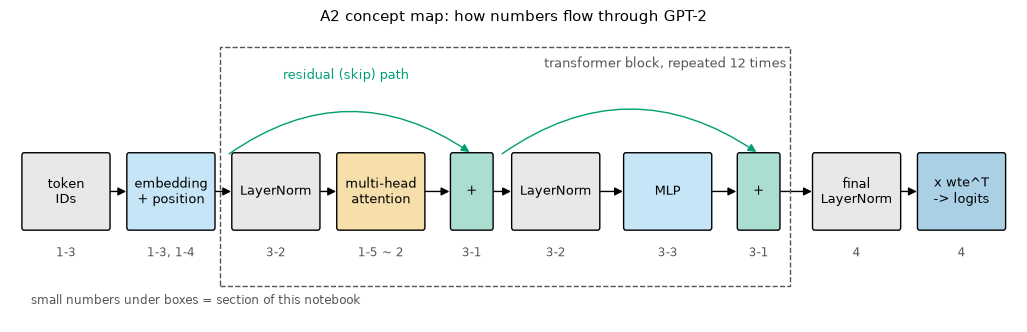

In [3]:
draw_concept_map()

**그림에서 볼 것**
- 점선 상자가 **블록** 하나입니다. GPT-2 small 은 같은 모양의 블록 12개를 차례로 지납니다(가중치는 블록마다 다릅니다).
- 블록 안에는 두 부품이 있습니다. 토큰끼리 정보를 섞는 **어텐션**(주황)과, 토큰 하나 안에서 변환하는 **MLP**(하늘색)입니다.
- 초록 화살표는 **잔차 연결**입니다. 부품을 거치지 않은 원래 값이 `+` 에서 다시 더해집니다.

## 1. 먼저 알아 둘 것

### 1-1. 벡터와 내적: "얼마나 비슷한가"를 재는 숫자

**한 줄 정의**: **벡터**는 숫자 여러 개를 한 줄로 묶은 것이고, **내적**(dot product)은 같은 자리끼리 곱해서 모두 더한 값입니다.

**왜 필요한가**: 트랜스포머에서 토큰 하나는 벡터 하나(GPT-2 small 은 숫자 768개)입니다. 어텐션은 "이 토큰이 저 토큰과 얼마나 관련 있나"를 **내적으로** 잽니다.

**숫자로 따라가기**: $a = (2, 1)$ 일 때

| 벡터 | 계산 | 내적 | 뜻 |
|---|---|---|---|
| $b = (1.8, 1.2)$ | 2×1.8 + 1×1.2 | 4.8 | 거의 같은 방향 |
| $c = (-1, 2)$ | 2×(−1) + 1×2 | 0 | 직각 |
| $d = (-2, -1)$ | 2×(−2) + 1×(−1) | −5 | 반대 방향 |

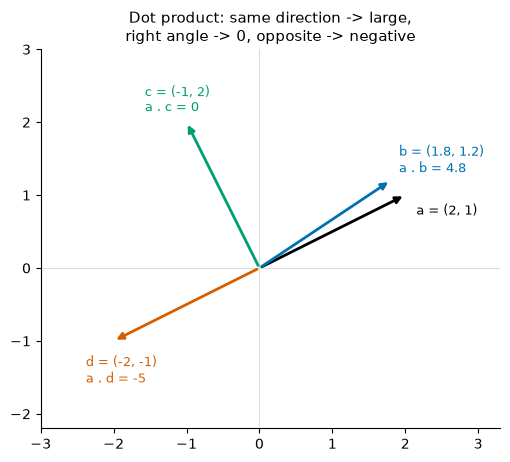

In [4]:
draw_dot_product()

**그림에서 볼 것**: 같은 쪽을 가리키는 $b$ 는 큰 양수, 직각인 $c$ 는 0, 반대쪽인 $d$ 는 음수입니다. 길이가 길수록 값의 크기도 커집니다.

**식과 근거**: $a \cdot b = \sum_i a_i b_i = |a|\,|b| \cos\theta$ ($\theta$ 는 두 벡터 사이의 각). 어텐션 점수가 Query 와 Key 의 내적이라는 것은 [3] 의 식 (1) 입니다.

**직접 바꿔 보기**: 아래 두 벡터를 바꿔 내적과 코사인($\cos\theta$, 길이를 뺀 방향만의 비슷함)을 계산해 보세요.

In [5]:
a_vec, b_vec = np.array([2.0, 1.0]), np.array([1.8, 1.2])
print("내적:", a_vec @ b_vec, " 코사인:", round(a_vec @ b_vec / np.linalg.norm(a_vec) / np.linalg.norm(b_vec), 3))

내적: 4.8  코사인: 0.992


### 1-2. 행렬 곱의 모양

**한 줄 정의**: 행렬 곱 $X W$ 는 "$X$ 의 행 하나 · $W$ 의 열 하나"라는 내적을 모든 짝에 대해 한꺼번에 하는 계산입니다.

**왜 필요한가**: 토큰 $T$ 개를 한 번에 계산하려고 토큰 벡터를 행으로 쌓은 행렬 $X$ (크기 $T \times 768$)를 씁니다.
트랜스포머 코드의 절반은 "지금 행렬 모양이 무엇인가"를 따라가는 일입니다.

**숫자로 따라가기**: 토큰 5개 $X$: (5, 768) 에 $W$: (768, 64) 를 곱하면 (5, 64) 가 됩니다. 안쪽 크기(768 과 768)가 같아야 곱할 수 있고, 결과는 바깥 크기(5 와 64)를 가집니다.

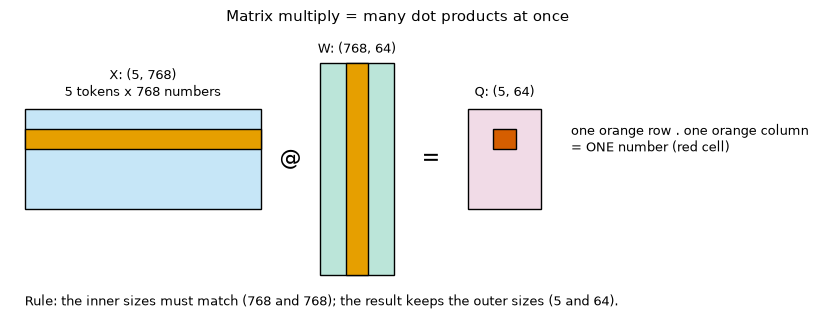

In [6]:
draw_matmul_shapes()
X_demo, W_demo = torch.randn(5, 768), torch.randn(768, 64)
assert (X_demo @ W_demo).shape == (5, 64)
assert torch.allclose((X_demo @ W_demo)[1, 2], X_demo[1] @ W_demo[:, 2])     # 결과의 한 칸 = 행 하나와 열 하나의 내적

**그림에서 볼 것**: 주황 행(토큰 하나)과 주황 열이 만나 결과의 빨간 칸 하나가 됩니다. 이 내적을 칸마다 반복한 것이 행렬 곱입니다.
위 코드의 두 번째 `assert` 가 이것을 숫자로 확인합니다.

### 1-3. 임베딩: 토큰 번호를 벡터로

**한 줄 정의**: **임베딩**은 토큰 번호마다 학습된 벡터를 하나씩 정해 둔 표(`wte`, 크기 50,257 × 768)에서, 번호에 해당하는 행을 꺼내는 것입니다.

**왜 필요한가**: 토큰 번호 464("The")와 1398(" class")의 크기 차이에는 아무 뜻이 없습니다. 계산할 수 있는 뜻을 담으려면 번호를 학습된 벡터로 바꿔야 합니다.

**숫자로 따라가기**: "The class was about" 의 번호 [464, 1398, 373, 546] 이면 표에서 464번, 1398번, 373번, 546번 행을 꺼내 (4, 768) 행렬을 만듭니다.

토큰 번호: [464, 1398, 373, 546] -> 임베딩 모양: (4, 768)


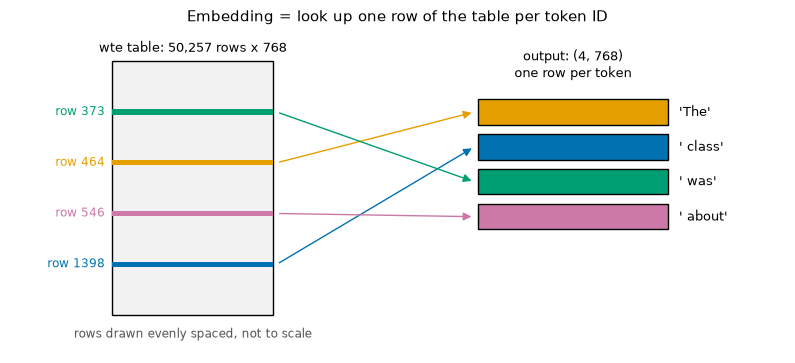

In [7]:
ids4 = tok("The class was about", return_tensors="pt").input_ids[0].to(device)
emb = sd["transformer.wte.weight"][ids4]
print("토큰 번호:", ids4.tolist(), "-> 임베딩 모양:", tuple(emb.shape))
assert torch.equal(emb, hf.transformer.wte(ids4))          # 표에서 행을 꺼내는 것 = 모델의 임베딩 층
draw_embedding_lookup(ids4.tolist(), [tok.decode(t) for t in ids4])

**그림에서 볼 것**: 왼쪽 큰 표에서 토큰 번호 자리의 행(색 줄)을 하나씩 꺼내 오른쪽에 쌓습니다. 계산은 이것이 전부입니다. 표의 숫자 자체가 학습으로 정해집니다.

학습된 표에서는 뜻이 비슷한 단어의 벡터가 비슷한 방향을 가리키는지, 실제 GPT-2 표로 확인해 봅니다(코사인 유사도).

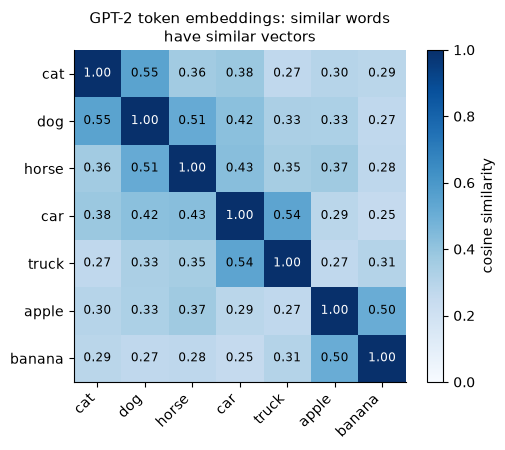

In [8]:
words = [" cat", " dog", " horse", " car", " truck", " apple", " banana"]
wid = [tok(w).input_ids[0] for w in words]
assert all(len(tok(w).input_ids) == 1 for w in words)        # 모두 한 토큰짜리 단어
E = F.normalize(sd["transformer.wte.weight"][wid].float(), dim=-1)
S_words = (E @ E.T).cpu().numpy()
draw_word_similarity([w.strip() for w in words], S_words)

**그림에서 볼 것**: 대체로 같은 무리끼리 더 비슷합니다(cat–dog 0.55, car–truck 0.54, apple–banana 0.50).
예외도 있습니다. cat–horse(0.36)는 cat–car(0.38)나 horse–car(0.43)보다 낮습니다. 값 전체가 0.25–0.55 사이라 차이가 아주 크지는 않다는 점도 보세요.
이 숫자는 이 노트북에서 GPT-2 표로 직접 계산한 것입니다. 누가 가르쳐 준 것이 아니라, 다음 토큰을 맞히도록 학습하는 동안 저절로 생긴 구조입니다.

### 1-4. 위치 임베딩: 순서를 알려 주기

**한 줄 정의**: 자리 번호(0, 1, 2, ...)마다 벡터를 하나씩 정해 둔 표(`wpe`, 크기 1,024 × 768)에서 꺼내 토큰 임베딩에 **더합니다**.

**왜 필요한가**: 마스크 없는 어텐션은 순서를 전혀 모릅니다. 입력 순서를 바꾸면 출력도 자리만 바뀔 뿐 값은 같습니다(아래 확인).
그래서 원래 트랜스포머는 위치 정보를 따로 넣었습니다 [3]. 위치가 없으면 "dog bites man" 과 "man bites dog" 은 같은 벡터 묶음입니다.
다만 GPT-2 처럼 causal mask 가 있는 언어 모델은 사정이 다릅니다. 위치 임베딩을 아예 빼도 표준 모델과 견줄 만한 성능을 낸다는 보고가 있고 [10],
저자들은 "자리마다 볼 수 있는 앞 토큰 수가 달라서 모델이 위치를 짐작할 수 있다"고 추측합니다 [10]. 순서를 완전히 모르는 것은 마스크 없는(양방향) 어텐션입니다.
원래 트랜스포머는 정해진 사인·코사인 값을 썼고, 학습하는 위치 벡터도 거의 같은 결과를 냈다고 보고했습니다 [3]. GPT-2 의 가중치에는 학습된 표 `wpe` 가 들어 있습니다.

**숫자로 따라가기**: " dog bites man" 과 " man bites dog" 은 같은 토큰 세 개를 순서만 바꾼 것입니다.
위치를 빼면 " dog" 토큰의 입력 벡터는 두 문장에서 똑같고, 마스크 없는 어텐션을 거친 " dog" 의 출력도 똑같습니다. 순서를 바꿔도 결과가 자리만 바뀔 뿐 같다는 뜻입니다.
위치를 더하면 " dog" 이 0번 자리냐 2번 자리냐에 따라 입력부터 달라집니다. 아래 코드는 GPT-2 첫 층의 Q, K, V 가중치로 이것을 확인합니다(head 하나, 마스크 없음).

위치 없이: ' dog' 의 입력·어텐션 출력이 두 문장에서 같음 / 위치를 더하면: 다름


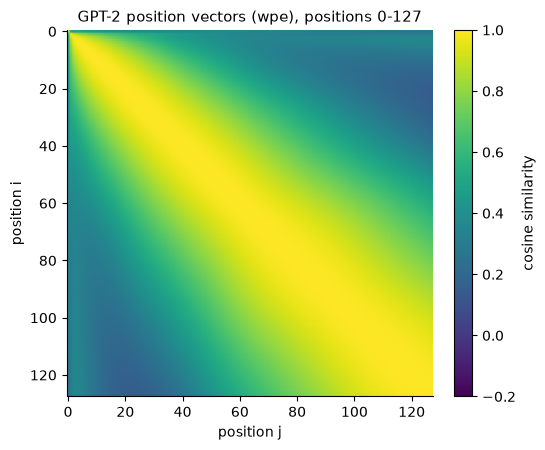

In [9]:
def dog_vectors(text, with_pos):
    """문장 안 " dog" 토큰의 (입력 벡터, 마스크 없는 head 하나 어텐션 출력)"""
    ids_b = tok(text, return_tensors="pt").input_ids[0].to(device)
    x = sd["transformer.wte.weight"][ids_b]
    if with_pos:
        x = x + sd["transformer.wpe.weight"][:len(ids_b)]
    q, k, v = (x @ sd["transformer.h.0.attn.c_attn.weight"] + sd["transformer.h.0.attn.c_attn.bias"]).split(768, dim=-1)
    q, k, v = q[:, :64], k[:, :64], v[:, :64]                       # 첫 head 만
    out = torch.softmax(q @ k.T / 8.0, -1) @ v                      # 마스크 없음
    pos = (ids_b == tok(" dog").input_ids[0]).nonzero()[0, 0]
    return x[pos], out[pos]

# 앞에 띄어쓰기를 붙여 두 문장이 같은 토큰 세 개(" dog", " bites", " man")로 이루어지게 한다
assert sorted(tok(" dog bites man").input_ids) == sorted(tok(" man bites dog").input_ids)
(x1, o1), (x2, o2) = dog_vectors(" dog bites man", False), dog_vectors(" man bites dog", False)
assert torch.equal(x1, x2) and torch.allclose(o1, o2, atol=1e-4)            # 위치 없음: 순서를 바꿔도 같다
(x1, o1), (x2, o2) = dog_vectors(" dog bites man", True), dog_vectors(" man bites dog", True)
assert not torch.allclose(x1, x2, atol=1e-3) and not torch.allclose(o1, o2, atol=1e-3)   # 위치 있음: 달라진다
print("위치 없이: ' dog' 의 입력·어텐션 출력이 두 문장에서 같음 / 위치를 더하면: 다름")

P = F.normalize(sd["transformer.wpe.weight"][:128].float(), dim=-1)
draw_position_similarity((P @ P.T).cpu().numpy())

**그림에서 볼 것**: 대각선 근처가 밝습니다. 가까운 자리끼리 위치 벡터가 비슷하고, 멀어질수록 덜 비슷합니다. 모델이 "가까운 자리"라는 개념을 학습으로 갖게 된 것입니다(이 노트북의 계산).

**식과 근거**: 입력 = $\text{wte}[\text{id}] + \text{wpe}[\text{position}]$. GPT-2 는 1,024 토큰까지 학습했고 [4], 위치 표도 1,024 칸입니다.
슬라이드 85쪽은 트랜스포머 구조 자체는 길이 제한이 없지만, 위치 정보를 학습한 길이까지만 믿을 수 있다고 설명합니다 [1].

### 1-5. Query, Key, Value

**한 줄 정의**: 토큰 벡터마다 행렬 세 개를 곱해 **Query**(내가 찾는 것), **Key**(내 이름표), **Value**(내가 넘겨줄 내용)를 만듭니다 [3].

**왜 필요한가**: "누구를 볼지"와 "무엇을 가져올지"를 따로 정하기 위해서입니다. 도서관에 비유하면 Query 는 검색어, Key 는 책 제목표, Value 는 책 내용입니다.
검색어와 제목표가 잘 맞는 책일수록 그 책의 내용을 많이 가져옵니다(비유는 이 노트북의 설명입니다).

**숫자로 따라가기**: "about" 의 Query 가 앞 토큰 네 개(자기 포함)의 Key 와 얼마나 맞는지 계산합니다. 2차원 장난감 숫자입니다.

In [10]:
toy_labels = ["The", "class", "was", "about"]
q_toy = np.array([1.0, 0.5])
K_toy = np.array([[0.2, 0.1], [1.5, 0.8], [0.3, -0.2], [0.8, 0.6]])
V_toy = np.array([[0.0, 1.0], [2.0, 0.5], [0.5, -1.0], [1.0, 1.5]])
score = K_toy @ q_toy / np.sqrt(2)
weight = np.exp(score) / np.exp(score).sum()
display(pd.DataFrame({"token": toy_labels, "q . k": (K_toy @ q_toy).round(3), "/ sqrt(2)": score.round(3),
                      "softmax weight": weight.round(3), "v": [tuple(v) for v in V_toy]}))
print("출력 = 가중치로 섞은 v =", (weight @ V_toy).round(3))
assert abs(weight.sum() - 1) < 1e-12

,token,q . k,/ sqrt(2),softmax weight,v
0,The,0.25,0.177,0.143,"(0.0, 1.0)"
1,class,1.90,1.344,0.459,"(2.0, 0.5)"
2,was,0.20,0.141,0.138,"(0.5, -1.0)"
3,about,1.10,0.778,0.261,"(1.0, 1.5)"


출력 = 가중치로 섞은 v = [1.247 0.625]


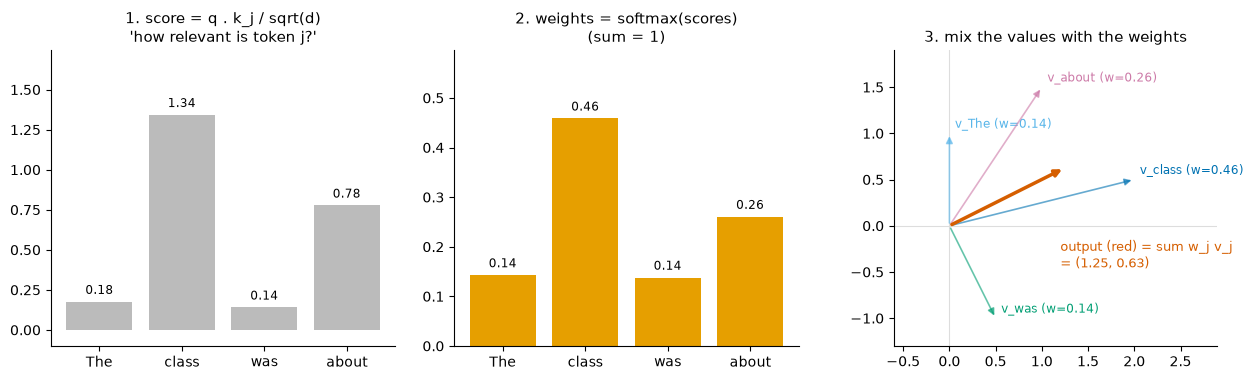

In [11]:
draw_qkv_steps(toy_labels, q_toy, K_toy, V_toy)

**그림에서 볼 것**
- 1: "class" 의 Key 가 Query 와 가장 잘 맞아 점수가 가장 높습니다.
- 2: softmax 를 거쳐 합이 1인 가중치가 됩니다. "class" 가 약 0.46 을 가져갑니다.
- 3: 출력(빨강)은 Value 네 개를 가중치만큼 섞은 것이라, 가중치가 큰 "class" 의 Value 쪽으로 끌려갑니다.

**식과 근거**: $\text{Attention}(Q, K, V) = \text{softmax}\!\left(QK^\top / \sqrt{d}\right) V$ ([3] 식 (1)).

**직접 바꿔 보기**: 위 셀에서 `q_toy` 를 `[0.0, 1.0]` 으로 바꾸면 어느 토큰을 가장 많이 볼까요? 바꾼 뒤 두 셀을 다시 실행해 보세요.

### 1-6. causal mask: 미래를 가리기

**한 줄 정의**: 각 토큰이 **자기와 자기보다 앞의 토큰만** 보도록, 뒤쪽 토큰 자리의 점수를 $-\infty$ 로 바꾸는 것입니다. softmax 를 거치면 그 자리는 0 이 됩니다.

**왜 필요한가**: 언어 모델은 다음 토큰을 맞히도록 학습합니다. 학습 때 뒤 토큰(정답)을 볼 수 있으면 그대로 베껴 버립니다.

**숫자로 따라가기**: 토큰 5개면 점수 칸은 5 × 5 = 25개이고, 그중 대각선 위 10칸이 가려집니다.

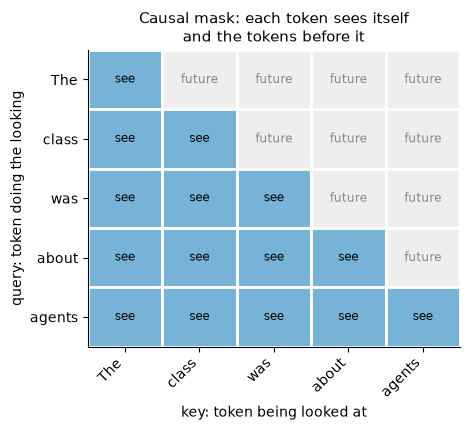

In [12]:
draw_causal_mask(["The", "class", "was", "about", "agents"])

**그림에서 볼 것**: 행이 "보는 토큰", 열이 "보이는 토큰"입니다. 첫 토큰 "The" 는 자기만 보고, 마지막 "agents" 는 다섯 개를 다 봅니다.

이제 셀프 어텐션 한 층을 짭니다 (슬라이드 33–42쪽 [1]).

1. 토큰 벡터 $X$ 에 행렬 세 개를 곱해 $Q, K, V$ 를 만듭니다.
2. $QK^\top$ 로 점수를 매기고 $\sqrt{d}$ 로 나눕니다(1-7 에서 이유).
3. 뒤 토큰 자리를 $-\infty$ 로 가립니다.
4. softmax 로 가중치를 만들고, 그 가중치로 $V$ 를 섞습니다.

In [13]:
def causal_self_attention(X, Wq, Wk, Wv):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    d = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d)
    T = X.shape[-2]
    mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=X.device), diagonal=1)
    scores = scores.masked_fill(mask, float("-inf"))
    A = torch.softmax(scores, dim=-1)        # A[i, j] = i번째 토큰이 j번째 토큰을 보는 비율
    return A @ V, A

T, d_model, d = 5, 16, 8
X = torch.randn(T, d_model)
Wq, Wk, Wv = (torch.randn(d_model, d) / math.sqrt(d_model) for _ in range(3))
out, A = causal_self_attention(X, Wq, Wk, Wv)

**확인.** 각 행은 합이 1이고, 대각선 위(미래)는 0이어야 합니다. PyTorch 내장 `scaled_dot_product_attention` 과 결과가 같아야 합니다.

내장 함수와 같음


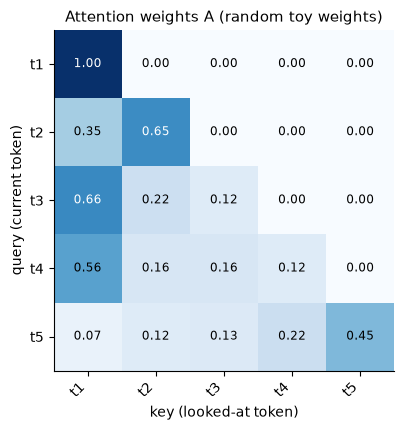

In [14]:
assert torch.allclose(A.sum(-1), torch.ones(T))
assert torch.all(A.triu(1) == 0)
ref = F.scaled_dot_product_attention((X @ Wq)[None], (X @ Wk)[None], (X @ Wv)[None], is_causal=True)[0]
assert torch.allclose(out, ref, atol=1e-5)
print("내장 함수와 같음")
draw_attention_heatmap(A.numpy(), ["t1", "t2", "t3", "t4", "t5"], "Attention weights A (random toy weights)")

**그림에서 볼 것**: 마스크 그림과 같은 자리(대각선 위)가 모두 0 입니다. 행마다 숫자를 더하면 1 입니다. 무작위 가중치라서 누구를 많이 보는지에는 뜻이 없습니다.

### 1-7. 왜 $\sqrt{d}$ 로 나누나

**한 줄 정의**: 점수 $q \cdot k$ 를 벡터 길이 $d$ 의 제곱근으로 나눠, 점수가 너무 커지지 않게 하는 것입니다.

**왜 필요한가**: 평균 0, 분산 1인 숫자 $d$ 개짜리 벡터 두 개의 내적은 분산이 $d$ 가 됩니다 [3]. $d$ 가 크면 점수 차이가 커져서 softmax 가 한 토큰에 거의 1을 몰아줍니다.
Vaswani 등은 이때 softmax 의 학습 신호(기울기)가 아주 작아질 것이라고 **추측**했고("We suspect ..."), 그래서 $\sqrt{d}$ 로 나눴습니다 [3]. 나누면 분산이 다시 1 근처로 돌아옵니다.

**숫자로 따라가기**: $d = 512$ 이면 점수의 표준편차가 $\sqrt{512} \approx 22.6$ 입니다. 점수 차이 22 는 확률로 $e^{22} \approx 36$억 배 차이입니다.

d=   8  내적 분산     8.1   sqrt(d)로 나눈 뒤 분산 1.01
d=  64  내적 분산    63.6   sqrt(d)로 나눈 뒤 분산 0.99
d= 512  내적 분산   503.2   sqrt(d)로 나눈 뒤 분산 0.98


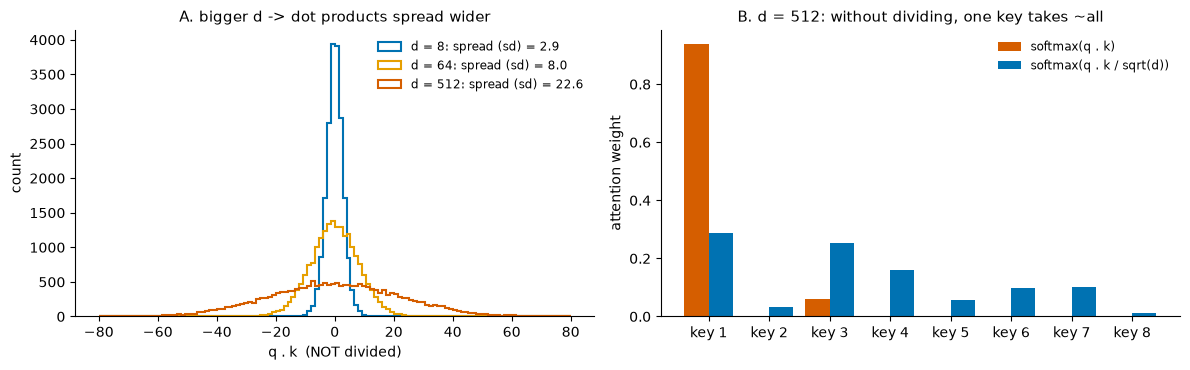

In [15]:
for dd in [8, 64, 512]:
    q, k = torch.randn(10000, dd), torch.randn(10000, dd)
    dots = (q * k).sum(-1)
    print(f"d={dd:4d}  내적 분산 {dots.var():7.1f}   sqrt(d)로 나눈 뒤 분산 {(dots / math.sqrt(dd)).var():.2f}")
draw_scaling()

**그림에서 볼 것**
- A: $d$ 가 커질수록 내적 값이 넓게 퍼집니다.
- B: $d = 512$ 에서 나누지 않으면(빨강) 한 Key 가 가중치를 거의 다 가져갑니다. 나누면(파랑) 여러 Key 에 나뉩니다.

**식과 근거**: Vaswani 등 3.2.1절과 각주 4 [3]: 성분이 평균 0, 분산 1 인 독립 변수면 $q \cdot k$ 의 분산은 $d_k$ 이고, 그래서 $1/\sqrt{d_k}$ 를 곱합니다.

## 2. 여러 머리 어텐션 (multi-head, 슬라이드 43–48쪽 [1])

**한 줄 정의**: 토큰 벡터에 행렬을 곱해 Q, K, V(각각 768개 숫자)를 만든 **뒤에**, 그것을 64개씩 12조각으로 나눠 조각마다 따로 어텐션을 합니다.
결과를 다시 이어 붙인 뒤 행렬 $W_O$ 를 한 번 더 곱합니다. 조각 하나를 **head** 라고 부릅니다.
큰 투영 결과를 12조각으로 자르는 것은, Vaswani 등이 head 마다 따로 둔 작은 투영 행렬 $W_i^Q, W_i^K, W_i^V$ 를 옆으로 이어 붙여 한 번에 곱한 것과 같습니다 [3].

**왜 필요한가**: 어텐션 한 번은 가중 평균 하나라서 "한 가지 관점"으로만 섞습니다. 여러 head 를 두면 서로 다른 위치에서 서로 다른 종류의 정보를 함께 가져올 수 있습니다 [3].

**숫자로 따라가기**: GPT-2 small 은 $768 = 12 \times 64$ 입니다. head 마다 Query·Key·Value 가 64차원이고, 점수표는 head 마다 $T \times T$ 하나씩, 모두 12개입니다.

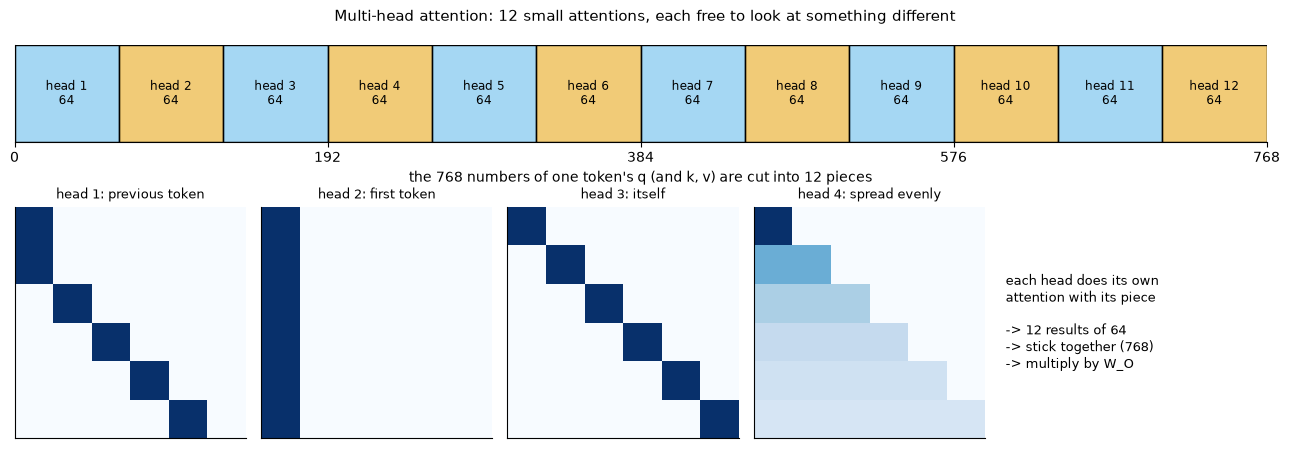

In [16]:
draw_multihead()

**그림에서 볼 것**: 위 막대처럼 768개를 12조각으로 자르고, 아래처럼 head 마다 다른 곳을 볼 수 있습니다.
아래 네 그림은 설명용으로 만든 무늬입니다. 실제 GPT-2 의 head 들이 이런 습관을 보이는지는 5절에서 확인합니다.

**식과 근거**: $\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, \dots, \text{head}_h) W^O$ ([3] 3.2.2절).

In [17]:
def multi_head_attention(X, Wqkv, bqkv, Wo, bo, n_head):
    """X: (T, D). GPT-2 방식: 한 행렬로 Q, K, V를 한꺼번에 만든다."""
    T, D = X.shape
    hd = D // n_head
    q, k, v = (X @ Wqkv + bqkv).split(D, dim=-1)
    q, k, v = (t.view(T, n_head, hd).transpose(0, 1) for t in (q, k, v))      # (head, T, hd)
    scores = q @ k.transpose(-2, -1) / math.sqrt(hd)
    mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=X.device), diagonal=1)
    A = torch.softmax(scores.masked_fill(mask, float("-inf")), dim=-1)
    y = (A @ v).transpose(0, 1).reshape(T, D)                                 # head 결과를 이어 붙임
    return y @ Wo + bo, A

## 3. 블록을 이루는 나머지 부품

### 3-1. 잔차 연결 (residual connection)

**한 줄 정의**: 부품의 출력만 쓰지 않고, **부품에 들어간 입력을 그대로 더해서** 내보냅니다. 출력 = $x + f(x)$.

**왜 필요한가**: 층이 깊어지면 학습이 어려워지는데, 각 층이 "입력에 더할 고침"만 배우게 하면 깊은 망도 학습이 쉬워집니다 [6].
원래 정보가 고속도로처럼 블록을 그대로 통과하고, 각 부품은 거기에 조금씩 보탭니다. 원래 트랜스포머도 부품마다 잔차 연결을 둡니다 [3].

**숫자로 따라가기**: $x = (1.0, 2.0)$, 부품의 출력 $f(x) = (0.1, -0.3)$ 이면 블록 출력은 $(1.1, 1.7)$ 입니다. 부품이 아무것도 못 배워도($f = 0$) $x$ 는 그대로 전달됩니다.

### 3-2. layer norm

**한 줄 정의**: 토큰 하나의 768개 숫자에서 평균을 빼고 표준편차로 나눠 평균 0, 표준편차 1로 맞춘 뒤, 학습된 값 $\gamma$(곱)와 $\beta$(더하기)로 다시 조정합니다 [5].

**왜 필요한가**: Ba 등은 뉴런 값들을 정규화하면 학습 시간을 줄일 수 있다는 생각에서 layer norm 을 제안했고, 실제로 학습 시간을 크게 줄였으며
순환 신경망에서 은닉 상태의 변동을 안정시키는 데 효과적이었다고 보고했습니다 [5]. 평균과 분산은 **토큰 하나 안의** 768개 숫자로 계산합니다(여러 문장을 묶어 계산하지 않음) [5].

**숫자로 따라가기**: [2, 4, 6, 8] 은 평균 5, 표준편차 2.236 이므로 [−1.34, −0.45, 0.45, 1.34] 가 됩니다.

**놓는 자리**: 원래 트랜스포머는 잔차를 더한 **뒤에** layer norm 을 했습니다(post-LN) [3]. GPT-2 는 부품에 들어가기 **전에** 하고(pre-LN), 마지막 블록 뒤에 하나를 더 둡니다 [4].

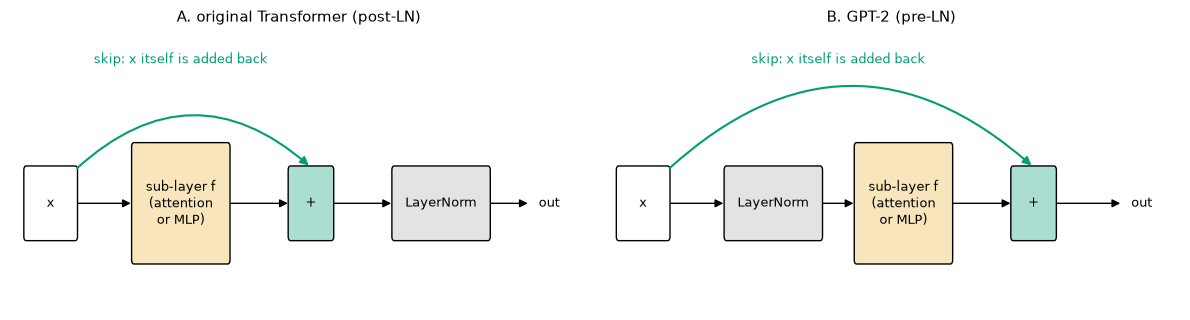

In [18]:
draw_residual()

**그림에서 볼 것**: 두 그림 모두 초록 화살표가 $x$ 를 `+` 로 바로 보냅니다. 차이는 LayerNorm 의 자리입니다. A 는 더한 뒤, B(GPT-2)는 부품에 들어가기 전입니다.

실제 GPT-2 에서 토큰 하나의 768개 숫자가 layer norm 을 지나며 어떻게 바뀌는지 봅니다(7번째 블록에 들어가기 직전 값).

장난감: [-1.34 -0.45  0.45  1.34]


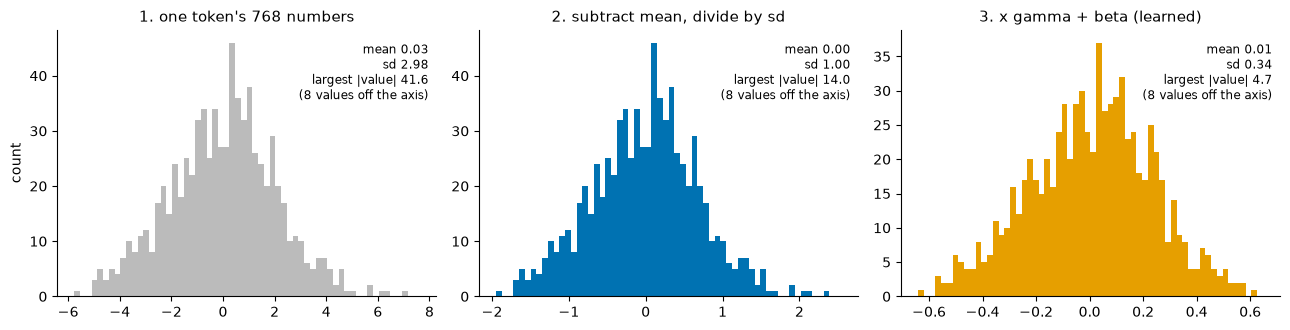

In [19]:
def layer_norm(x, w, b, eps=1e-5):
    mu = x.mean(-1, keepdim=True)
    var = x.var(-1, keepdim=True, unbiased=False)
    return (x - mu) / torch.sqrt(var + eps) * w + b

toy = torch.tensor([2.0, 4.0, 6.0, 8.0])
print("장난감:", layer_norm(toy, torch.ones(4), torch.zeros(4), eps=0).numpy().round(2))
assert torch.allclose(layer_norm(toy, torch.ones(4), torch.zeros(4), eps=0), torch.tensor([-1.3416, -0.4472, 0.4472, 1.3416]), atol=1e-4)

with torch.no_grad():
    hs = hf(tok("The class was about how agents work", return_tensors="pt").input_ids.to(device),
            output_hidden_states=True).hidden_states
x_tok = hs[6][0, 3].float()                               # 7번째 블록 입력, 4번째 토큰
assert torch.allclose(layer_norm(x_tok, sd["transformer.h.6.ln_1.weight"], sd["transformer.h.6.ln_1.bias"]),
                      F.layer_norm(x_tok, (768,), sd["transformer.h.6.ln_1.weight"], sd["transformer.h.6.ln_1.bias"]), atol=1e-4)
draw_layernorm(x_tok.cpu().numpy(), sd["transformer.h.6.ln_1.weight"].cpu().numpy(), sd["transformer.h.6.ln_1.bias"].cpu().numpy())

**그림에서 볼 것**
- 1: 원래 값은 대부분 작지만 아주 큰 값이 몇 개 있습니다(오른쪽 위 "largest |value|").
- 2: 평균 0, 표준편차 1로 맞춰졌습니다.
- 3: 학습된 $\gamma, \beta$ 로 다시 조정되어 평균과 표준편차가 다시 달라집니다. "무조건 0과 1"이 아니라 "맞춘 뒤 필요한 만큼 다시 조정"입니다.

숫자는 이 노트북에서 GPT-2 로 계산한 것입니다.

### 3-3. MLP 와 GELU

**한 줄 정의**: **MLP** 는 토큰마다 따로 768 → 3,072 → 768 로 늘렸다 줄이는 두 번의 행렬 곱이고, 그 사이에 **GELU** 라는 휘는 함수를 넣습니다.

**왜 필요한가**: 어텐션은 토큰끼리 섞는 일을, MLP 는 토큰 하나 안에서 숫자를 바꾸는 일을 맡습니다. 행렬 곱만 이어 붙이면 결국 행렬 곱 하나와 같으므로, 사이에 휘는 함수가 있어야 복잡한 변환을 배울 수 있습니다.
원래 트랜스포머는 512 → 2,048 → 512 (4배)에 ReLU 를 썼고, 위치마다 따로 똑같이 적용했습니다 [3]. GELU 는 $x \cdot \Phi(x)$ ($\Phi$ 는 표준정규분포의 누적분포함수)입니다 [7].

**숫자로 따라가기**: 블록 하나의 MLP 파라미터는 $768 \times 3072 + 3072 + 3072 \times 768 + 768 = 4{,}722{,}432$ 개로, 어텐션($2{,}362{,}368$ 개)의 약 두 배입니다.

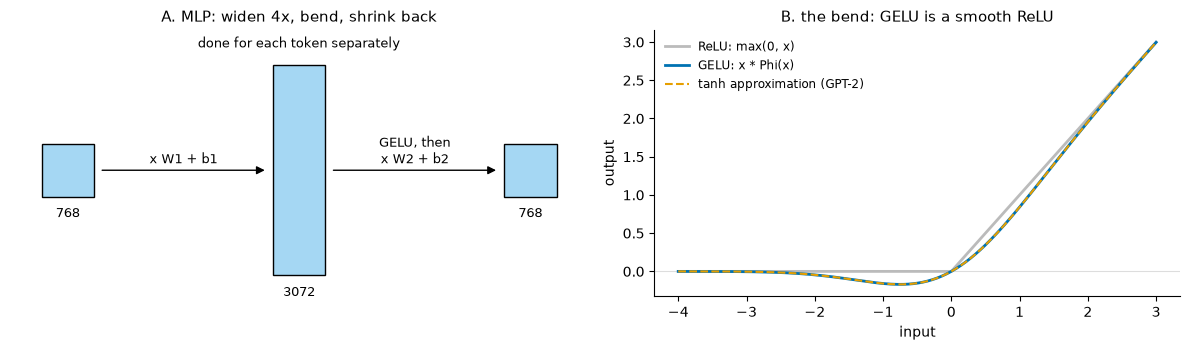

In [20]:
draw_mlp_gelu()
assert sd["transformer.h.0.mlp.c_fc.weight"].shape == (768, 3072)       # GPT-2 의 MLP 는 4배로 넓힌다
assert cfg.activation_function == "gelu_new"                           # tanh 근사 GELU
mlp_params = 768 * 3072 + 3072 + 3072 * 768 + 768
attn_params = 768 * 2304 + 2304 + 768 * 768 + 768
assert mlp_params == 4_722_432 and attn_params == 2_362_368

**그림에서 볼 것**
- A: 768개를 3,072개로 넓혔다가 다시 768개로 줄입니다. 토큰마다 따로 합니다.
- B: GELU(파랑)는 ReLU(회색)를 부드럽게 만든 모양입니다. GPT-2 는 tanh 를 쓴 근사식(주황 점선)을 씁니다.
  OpenAI 원본 코드의 `gelu` 함수가 이 식이고 [11], Hugging Face 의 GPT-2 설정도 `activation_function` 이 `gelu_new`(같은 tanh 근사)입니다(위 셀의 `assert`).

## 4. GPT-2 를 직접 계산하기 (슬라이드 49–60쪽 [1])

부품을 모두 이어 붙입니다. 아래 그림은 토큰 $T$ 개를 넣었을 때 단계마다 행렬 모양이 어떻게 바뀌는지 보여 줍니다.

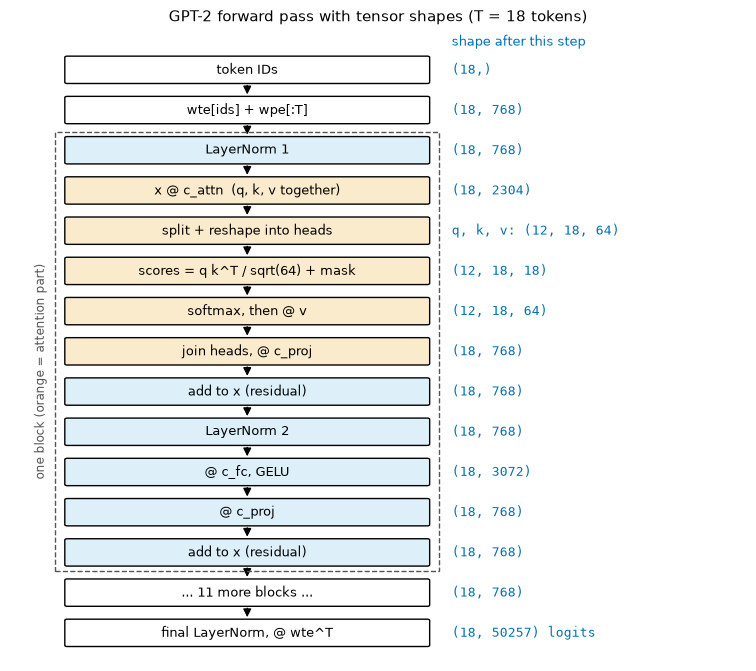

In [21]:
draw_block_shapes(T=18)

**그림에서 볼 것**
- 주황 칸이 어텐션 부분입니다. $(T, 768)$ 이 $(T, 2304)$ 로 넓어졌다가(Q, K, V 를 한꺼번에), head 12개로 나뉘고, 점수표 $(12, T, T)$ 를 거쳐 다시 $(T, 768)$ 이 됩니다.
- 하늘색 칸이 블록의 나머지(잔차, LayerNorm, MLP)입니다. 블록을 나올 때 모양은 들어갈 때와 같은 $(T, 768)$ 이라 블록을 몇 개든 이어 붙일 수 있습니다.
- 마지막에 토큰 임베딩 표 `wte` 를 다시 곱해 어휘 50,257개의 logit 을 냅니다. 입력 임베딩과 출력 층이 같은 표를 같이 씁니다(원래 트랜스포머도 같은 방식 [3]).

이제 Hugging Face 에서 GPT-2 가중치만 꺼내 위 계산을 그대로 해 봅니다.

**가중치 이름 읽기**: `c_attn` 은 Q·K·V 를 한꺼번에 만드는 행렬, `c_proj` 는 결과를 다시 768 로 돌리는 행렬(어텐션과 MLP 양쪽에 있음), `c_fc` 는 MLP 의 첫 행렬입니다.
이름은 OpenAI 원본 코드에서 이 층들을 만드는 `conv1d` 함수 호출에서 왔습니다 [11]. 이 함수는 가중치를 (입력, 출력) 모양으로 저장하므로 [11],
Hugging Face 의 `Conv1D` 도 일반 선형층과 달리 가중치가 전치된 꼴이고 [12], 그래서 아래 코드는 `x @ W` 를 전치 없이 곱합니다.

In [22]:
assert sd["transformer.h.0.attn.c_attn.weight"].shape == (768, 2304)    # (입력 768, 출력 Q+K+V 2304)
def gpt2_forward(ids, return_attn=False):
    T = len(ids)
    x = sd["transformer.wte.weight"][ids] + sd["transformer.wpe.weight"][:T]
    attns = []
    for i in range(cfg.n_layer):
        p = f"transformer.h.{i}."
        h = layer_norm(x, sd[p + "ln_1.weight"], sd[p + "ln_1.bias"])
        a, A = multi_head_attention(h, sd[p + "attn.c_attn.weight"], sd[p + "attn.c_attn.bias"],
                                    sd[p + "attn.c_proj.weight"], sd[p + "attn.c_proj.bias"], cfg.n_head)
        x = x + a
        h = layer_norm(x, sd[p + "ln_2.weight"], sd[p + "ln_2.bias"])
        h = F.gelu(h @ sd[p + "mlp.c_fc.weight"] + sd[p + "mlp.c_fc.bias"], approximate="tanh")
        x = x + h @ sd[p + "mlp.c_proj.weight"] + sd[p + "mlp.c_proj.bias"]
        attns.append(A)
    x = layer_norm(x, sd["transformer.ln_f.weight"], sd["transformer.ln_f.bias"])
    logits = x @ sd["transformer.wte.weight"].T
    return (logits, attns) if return_attn else logits

**확인.** 직접 계산한 logit 과 Hugging Face 모델의 logit 이 같아야 합니다. 계산 순서가 조금 달라 생기는 아주 작은 오차(소수점 아래 셋째 자리 미만)만 허용합니다.

In [23]:
text = "The class was about how agents work, and how to build AI systems that use tools."
ids = tok(text, return_tensors="pt").input_ids[0].to(device)
with torch.no_grad():
    mine = gpt2_forward(ids)
    ref = hf(ids[None]).logits[0]
diff = (mine - ref).abs().max().item()
print("토큰 수:", len(ids), " 최대 차이:", diff)
assert diff < 1e-3
assert torch.equal(mine.argmax(-1), ref.argmax(-1))     # 위치마다 1등 토큰도 같다

토큰 수: 18  최대 차이: 8.392333984375e-05


## 4-1. 파라미터 수

파라미터 수를 손으로 세어 봅니다. 출력 층은 `wte` 를 같이 쓰므로 한 번만 셉니다.

손으로 센 값 124,439,808  /  모델 124,439,808


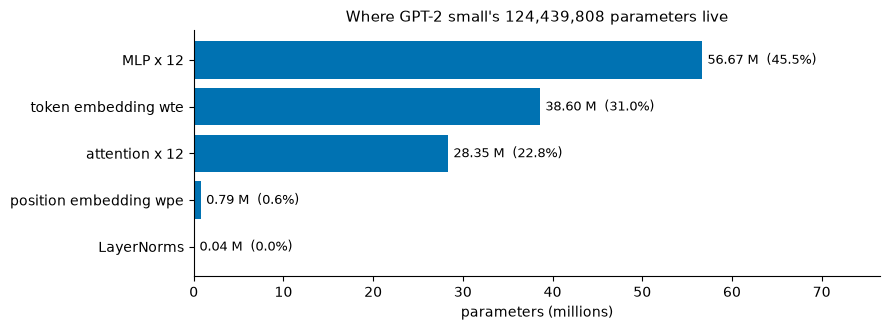

In [24]:
D, V, P, L = cfg.n_embd, cfg.vocab_size, cfg.n_positions, cfg.n_layer
per_block = (2 * D) + (D * 3 * D + 3 * D) + (D * D + D) + (2 * D) + (D * 4 * D + 4 * D) + (4 * D * D + D)
total = V * D + P * D + L * per_block + 2 * D
print(f"손으로 센 값 {total:,}  /  모델 {hf.num_parameters():,}")
assert total == hf.num_parameters()
parts = {"token embedding wte": V * D, "position embedding wpe": P * D,
         "attention x 12": L * attn_params, "MLP x 12": L * mlp_params, "LayerNorms": L * 4 * D + 2 * D}
assert sum(parts.values()) == total
draw_param_breakdown(parts, total)

**그림에서 볼 것**: 가장 큰 덩어리는 MLP 12개이고, 그다음이 토큰 임베딩 표(약 31%)입니다. 블록 하나 안에서 MLP 가 어텐션의 약 두 배입니다 ($8D^2$ 대 $4D^2$).

GPT-2 보고서의 표에는 가장 작은 모델이 117M 으로 적혀 있지만 [4], 공개된 가중치를 실제로 세면 위처럼 124,439,808 개입니다.
OpenAI 는 GPT-2 코드 저장소에서 처음 발표한 파라미터 수가 잘못 계산되었고, 그래서 small 이 117M 으로 알려졌다고 밝혔습니다 [11].

## 5. 실제 head 는 어디를 보나

직접 짠 함수가 돌려준 어텐션 가중치로 head 마다의 습관을 찾아봅니다.

- **바로 앞 토큰을 보는 head**: $A[t, t-1]$ 의 평균이 큰 head
- **첫 토큰을 보는 head**: 할 일이 없을 때 첫 토큰에 가중치를 몰아 두는 습관이 여러 언어 모델에서 보고되었고, "attention sink" 라고 부릅니다 [9].

앞 토큰을 가장 많이 보는 head: 층 4 head 11 (평균 1.00)
첫 토큰에 평균 0.5 넘게 몰아주는 head: 91개 / 144개


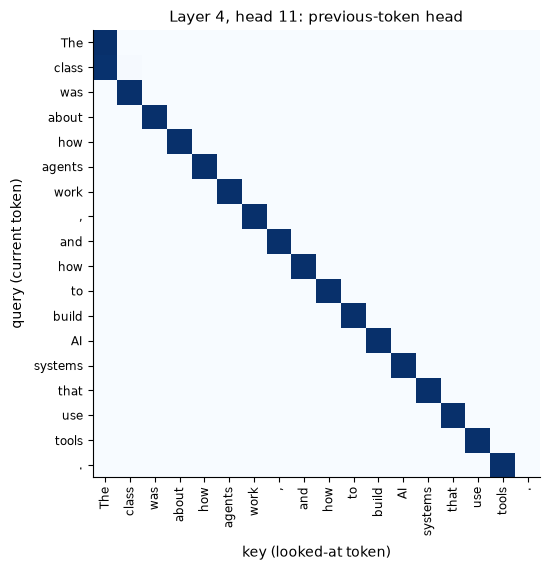

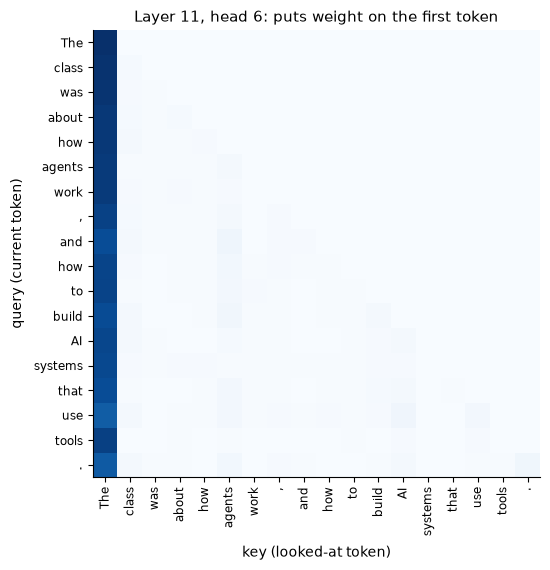

In [25]:
with torch.no_grad():
    _, attns = gpt2_forward(ids, return_attn=True)
A_all = torch.stack(attns).cpu()            # (층, head, T, T)
T = A_all.shape[-1]
prev_score = A_all[..., torch.arange(1, T), torch.arange(0, T - 1)].mean(-1)
sink_score = A_all[..., 1:, 0].mean(-1)
li, hi = divmod(prev_score.argmax().item(), cfg.n_head)
print(f"앞 토큰을 가장 많이 보는 head: 층 {li} head {hi} (평균 {prev_score.max():.2f})")
print(f"첫 토큰에 평균 0.5 넘게 몰아주는 head: {(sink_score > 0.5).sum().item()}개 / {L * cfg.n_head}개")

labels = [tok.decode(t) for t in ids]
draw_attention_heatmap(A_all[li, hi].numpy(), labels, f"Layer {li}, head {hi}: previous-token head")
sink_h = int(sink_score[11].argmax())
draw_attention_heatmap(A_all[11, sink_h].numpy(), labels, f"Layer 11, head {sink_h}: puts weight on the first token")

**그림에서 볼 것**
- 첫 그림: 대각선 바로 아래 한 줄이 진합니다. 모든 토큰이 "바로 앞 토큰"을 봅니다.
- 둘째 그림: 첫 열(첫 토큰 "The")이 진합니다. 내용과 상관없이 첫 토큰에 가중치가 몰립니다.
- 어느 head 가 어떤 습관을 보이는지는 이 노트북에서 찾은 결과입니다.

### 복사하는 head (induction head)

아무 뜻 없는 토큰 50개를 두 번 이어 붙여 넣으면, 모델은 두 번째 부분을 아주 잘 맞힙니다. 앞에서 본 것을 "베껴" 쓰기 때문입니다.
이 일을 하는 head 는 지금 토큰이 앞에서 나왔던 자리를 찾아 **그 다음 토큰**을 봅니다([A][B] … [A] → [B]). 이런 head 를 induction head 라고 합니다 [8].
Olsson 등은 이것이 프롬프트 안의 예시를 보고 따라 하는 능력(in-context learning)의 큰 부분을 맡을 수 있다는 가설을 냈습니다(큰 모델에서는 간접 증거) [8].

앞 50개 평균 손실 11.98,  반복된 뒤 50개 평균 손실 0.21
induction 점수 상위 head: [((5, 5), 0.95), ((6, 9), 0.93), ((7, 10), 0.92)]


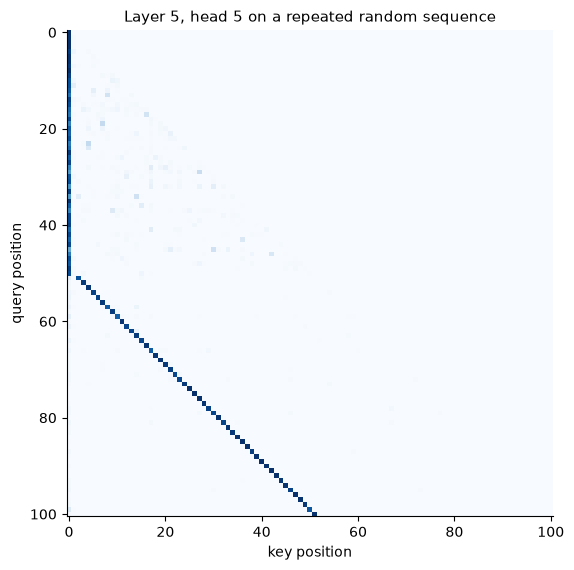

In [26]:
g = torch.Generator().manual_seed(0)
rand = torch.randint(1000, 20000, (50,), generator=g)
rep = torch.cat([torch.tensor([tok.bos_token_id]), rand, rand]).to(device)
with torch.no_grad():
    logits_rep, attns_rep = gpt2_forward(rep, return_attn=True)
logp = torch.log_softmax(logits_rep[:-1], -1)[torch.arange(len(rep) - 1), rep[1:]]
first, second = -logp[:50].mean().item(), -logp[51:].mean().item()
print(f"앞 50개 평균 손실 {first:.2f},  반복된 뒤 50개 평균 손실 {second:.2f}")
assert second < first / 2        # 반복 부분을 훨씬 잘 맞힌다

A_rep = torch.stack(attns_rep).cpu()
t = torch.arange(52, 101)                   # 두 번째 부분의 위치
induction = A_rep[..., t, t - 49].mean(-1)  # 앞에서 같은 토큰이 나온 자리의 다음 자리
top = torch.topk(induction.flatten(), 3)
print("induction 점수 상위 head:", [(divmod(i, cfg.n_head), round(v, 2)) for i, v in zip(top.indices.tolist(), top.values.tolist())])
il, ih = divmod(top.indices[0].item(), cfg.n_head)
draw_attention_heatmap(A_rep[il, ih].numpy(), [""] * len(rep), f"Layer {il}, head {ih} on a repeated random sequence")

**그림에서 볼 것**: 주 대각선(자기 자신)은 진하지 않습니다. 그림은 두 부분으로 나뉩니다.
- 앞 절반(첫 구간, 0–50행): 거의 모든 가중치가 첫 열, 즉 시작 표시에 몰려 있습니다(5절 앞부분에서 본 attention sink 와 같은 습관).
- 뒤 절반(두 번째 구간, 51행부터): 진한 점들이 대각선 한 줄을 이룹니다. 각 행에서 자기 자리보다 **49칸 앞**, 즉 첫 구간에서 같은 토큰이 나왔던 자리의 **바로 다음 자리**입니다.
  그 자리의 토큰이 곧 "다음에 올 토큰"이라 베낄 수 있습니다.

## 연습 문제

1. `causal_self_attention` 에서 mask 를 빼면 학습할 때 무슨 문제가 생기나요?
2. 문장 길이가 $T$ 일 때 head 하나의 점수표 크기는? 길이가 두 배가 되면 점수 계산량은 몇 배가 되나요?
3. 위치 임베딩을 빼면 "dog bites man" 과 "man bites dog" 를 구별할 수 있을까요? (1-4 의 코드를 떠올려 보세요.)
4. GPT-2 small 에서 파라미터가 가장 많은 부품 하나(행렬 하나)는 무엇인가요?
5. `draw_block_shapes` 그림에서 $(12, T, T)$ 모양의 점수표는 길이 $T = 1{,}024$ 일 때 숫자 몇 개인가요?

<details><summary>답 보기</summary>

1. 모델이 정답(다음 토큰)을 미리 보고 베낄 수 있게 됩니다. 학습 손실은 쉽게 내려가지만, 실제로 글을 쓸 때는 미래 토큰이 없으므로 쓸모가 없습니다.
2. $T \times T$ 입니다. 길이가 두 배면 점수 계산과 메모리가 약 네 배가 됩니다. 이것이 A3 에서 다루는 $O(n^2)$ 문제입니다.
3. 마스크 없는 어텐션이라면 1-4 처럼 구별하지 못합니다. GPT-2 같은 causal 언어 모델은 위치 임베딩이 없어도 causal mask 덕에 위치를 어느 정도 알아내며,
   그런 모델이 표준 모델과 견줄 만한 성능을 낸다는 보고가 있습니다 [10]. 그래서 "구별 못 한다"는 마스크 없는 경우에만 맞는 말입니다.
4. 토큰 임베딩 `wte` 입니다. 50,257 × 768 ≈ 3,860만 개로 전체의 약 31% 입니다.
5. $12 \times 1024 \times 1024 \approx 1{,}260$만 개입니다. 이것이 층마다 하나씩 생깁니다.
</details>

## 정리

- 셀프 어텐션은 Query–Key 내적으로 "누구를 볼지" 정하고, softmax 가중치로 Value 를 섞는 계산입니다. causal mask 가 미래를 가리고, $\sqrt{d}$ 로 나눠 점수가 너무 커지지 않게 합니다.
- GPT-2 는 임베딩 → (layer norm, 어텐션, 잔차, layer norm, MLP, 잔차) × 12 → logit 이 전부입니다. 이것만으로 Hugging Face 결과를 그대로 재현했습니다.
- head 마다 습관이 있습니다. 앞 토큰 보기, 첫 토큰에 몰아두기, 앞에서 본 것 베끼기 등입니다.

## 실제와 다른 점

- 2절 multi-head 그림의 네 무늬, 1-5 의 Q·K·V 숫자, 1-7 의 점수는 설명용 장난감입니다.
- 직접 짠 `gpt2_forward` 는 배치(여러 문장 한꺼번에)와 KV 캐시를 지원하지 않습니다. 계산 내용은 같습니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Yang, Ryan, Yang. CS329Z Lecture 2 "LLMs for Builders" 슬라이드 (Stanford, 2026). [PDF](https://web.stanford.edu/class/cs329z/slides/lecture02.pdf), 사본 `data/lecture02.pdf` | 24–60쪽 구조 설명, 32쪽 강조, 33–42쪽 어텐션, 43–48쪽 multi-head, 49–60쪽 디코더 전용 트랜스포머, 85쪽 문맥 길이와 위치 정보 |
| [2] | Michael Ryan. Stanford CS329Z Lecture 2 영상 (Stanford Online, 2026). [YouTube](https://www.youtube.com/watch?v=Vr1NzH8bT44) | 영상 구간 16:03 ~ 28:27 |
| [3] | Vaswani 등. Attention Is All You Need. NeurIPS 2017. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762) (사본 `data/`) | 식 (1) 어텐션, 3.2.1절·각주 4 의 $\sqrt{d_k}$, 3.2.2절 multi-head, 3.1절 잔차 + LayerNorm(post-LN), 3.3절 FFN 512 → 2,048 과 ReLU, 3.4절 임베딩·출력 가중치 공유, 3.5절 위치 정보와 학습 위치 벡터 비교 |
| [4] | Radford 등. Language Models are Unsupervised Multitask Learners. OpenAI 보고서 (2019). [PDF](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) | 2.3절 pre-LN 과 마지막 LayerNorm, 문맥 1,024 토큰, 표 2 의 117M·12층·768차원 |
| [5] | Ba, Kiros, Hinton. Layer Normalization (2016). [arXiv:1607.06450](https://arxiv.org/abs/1607.06450) | 한 샘플의 층 안 값으로 평균·분산 계산, 학습된 bias 와 gain |
| [6] | He, Zhang, Ren, Sun. Deep Residual Learning for Image Recognition. CVPR 2016, 770–778쪽. [arXiv:1512.03385](https://arxiv.org/abs/1512.03385) | 잔차 학습이 깊은 망의 학습을 쉽게 한다 |
| [7] | Hendrycks, Gimpel. Gaussian Error Linear Units (GELUs) (2016). [arXiv:1606.08415](https://arxiv.org/abs/1606.08415) | GELU $= x\,\Phi(x)$ |
| [8] | Olsson 등. In-context Learning and Induction Heads (2022). [arXiv:2209.11895](https://arxiv.org/abs/2209.11895) | induction head 의 [A][B] … [A] → [B] 동작, in-context learning 과의 관계(가설) |
| [9] | Xiao, Tian, Chen, Han, Lewis. Efficient Streaming Language Models with Attention Sinks. ICLR 2024. [arXiv:2309.17453](https://arxiv.org/abs/2309.17453) | 첫 토큰에 큰 어텐션이 몰리는 attention sink |
| [10] | Haviv, Ram, Press, Izsak, Levy. Transformer Language Models without Positional Encodings Still Learn Positional Information. Findings of EMNLP 2022. [arXiv:2203.16634](https://arxiv.org/abs/2203.16634) | 위치 임베딩 없는 causal 언어 모델도 표준 모델과 견줄 만하다, causal attention 으로 위치를 짐작한다는 저자들의 추측 |
| [11] | OpenAI. gpt-2 코드 저장소. [GitHub](https://github.com/openai/gpt-2) | README 의 파라미터 수 정정(small 이 117M 으로 알려진 이유), `src/model.py` 의 tanh `gelu` 와 `conv1d`(`c_attn`, `c_proj`, `c_fc`, 가중치 모양 `[1, 입력, 출력]`) |
| [12] | Hugging Face transformers. `pytorch_utils.py` 의 `Conv1D` 설명 (실습 환경에 설치된 판) | "선형층처럼 작동하지만 가중치가 전치되어 있다" |

단어·위치 유사도, head 별 습관, 파라미터 수, 손실 값 같은 숫자 결과는 출처가 아니라 이 노트북에서 GPT-2 로 직접 계산한 값입니다.